# Grad Café Admissions Data Cleaning, Feature Engineering & Statistical Analysis
**Course:** Johns Hopkins University — Principles of Software Development / Software Concepts (EN.605.601)  
**Module:** Module 8 — Data Preparation & Statistics Assignment  
**Author:** Noella Formin (`Noella96` / `Achaformin@gmail.com`)  
**Environment:** Amazon SageMaker Notebook Instance (`ml.t3.medium`) / Python 3.12 Kernel  

---

## Assignment Overview & Workflow Architecture
In this assignment, we extend the cloud pipeline established in Module 7 into an end-to-end data-cleaning and exploratory-analysis workflow:
1. **Cloud Data Ingestion:** Ingest raw Grad Café JSON data from Amazon S3 into the SageMaker environment using `boto3`.
2. **Inspection & Missingness:** Preserve an immutable `raw_df` copy and compute column-level missingness metrics.
3. **Data Cleaning & Standardization:** Split unstructured fields, standardize text casing/whitespace, parse decision dates using term-inferred years, and enforce valid domain categorical values.
4. **Validation & Derived Features:** Perform vectorized feature engineering (`has_valid_gpa`, `has_valid_gre`, `days_to_decision`, `decision_speed`, `application_season`) and output validation summaries.
5. **Descriptive Statistics & Outlier Analysis:** Compute 9 descriptive metrics across numeric features and flag outliers using `scipy.stats.zscore`.
6. **Hypothesis Testing via SciPy:** Execute Pearson/Spearman correlations, two-sample tests on admissions GPA (Welch $t$-test and Mann-Whitney $U$), and Chi-Square contingency tests.
7. **Publication Visualizations:** Generate 6 publication-grade figures with NumPy regression fits, legends, and metric annotations.
8. **Cloud Persistence & Teardown:** Export `cleaned_gradcafe.json` and upload back to Amazon S3 via `boto3`.

## 1. Setup, Environment Configuration & Amazon S3 Data Ingestion
Import standard data science packages (`pandas`, `numpy`, `scipy`, `matplotlib`, `seaborn`, `boto3`) and initialize S3 connection parameters using the AWS credential provider chain.

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import boto3
from botocore.exceptions import ClientError, BotoCoreError

# Configure Matplotlib / Seaborn aesthetics
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "semibold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 16,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# S3 Configuration Parameters
BUCKET_NAME = os.environ.get("S3_BUCKET_NAME", "grad-cafe-nf-594366804861")
OBJECT_KEY = os.environ.get("S3_OBJECT_KEY", "applicant_data.json")
LOCAL_RAW_PATH = "applicant_data.json"
AWS_REGION = os.environ.get("AWS_REGION", "us-east-1")

print(f"[+] Active Python Environment: {sys.executable}")
print(f"[+] Target S3 Bucket: {BUCKET_NAME}")
print(f"[+] Target S3 Key: {OBJECT_KEY}")
print(f"[+] Target AWS Region: {AWS_REGION}")

[+] Active Python Environment: /Users/sourav/Desktop/jhu_software_concepts/.venv/bin/python3.12
[+] Target S3 Bucket: grad-cafe-nf-594366804861
[+] Target S3 Key: applicant_data.json
[+] Target AWS Region: us-east-1


In [2]:
# Download dataset from Amazon S3 using boto3 workflow
s3_client = boto3.client("s3", region_name=AWS_REGION)

try:
    print(f"[*] Downloading s3://{BUCKET_NAME}/{OBJECT_KEY} -> {LOCAL_RAW_PATH}...")
    s3_client.download_file(BUCKET_NAME, OBJECT_KEY, LOCAL_RAW_PATH)
    file_size_mb = os.path.getsize(LOCAL_RAW_PATH) / (1024 * 1024)
    print(f"[✓] Successfully retrieved dataset from S3: {file_size_mb:.2f} MB")
except (ClientError, BotoCoreError) as err:
    print(f"[!] S3 retrieval notice: {err}. Checking local fallback...")
    if not os.path.exists(LOCAL_RAW_PATH):
        fallback_path = os.path.abspath("../module_6/src/data/applicant_data.json")
        if os.path.exists(fallback_path):
            import shutil
            shutil.copy(fallback_path, LOCAL_RAW_PATH)
            print(f"[✓] Loaded local fallback from: {fallback_path}")
        else:
            raise FileNotFoundError(f"Could not locate applicant_data.json in S3 or locally.")
    else:
        print(f"[✓] Using existing local copy: {LOCAL_RAW_PATH}")

[*] Downloading s3://grad-cafe-nf-594366804861/applicant_data.json -> applicant_data.json...


[✓] Successfully retrieved dataset from S3: 11.04 MB


## 2. Raw Dataset Inspection & Missingness Reporting
Load the downloaded JSON data into a Pandas DataFrame, display initial sample records, preserve an immutable `raw_df` copy, and compute column-level missingness distributions.

In [3]:
# Load JSON data into Pandas DataFrame
with open(LOCAL_RAW_PATH, "r", encoding="utf-8") as f_in:
    raw_records = json.load(f_in)

df_loaded = pd.DataFrame(raw_records)

# Display first 5 rows of the raw dataset
print(f"[+] Raw Records Loaded: {len(df_loaded):,}")
display(df_loaded.head(5))

[+] Raw Records Loaded: 30,500


,program,comments,date_added,url,status,term,US/International,Degree,GPA,GRE,GRE V,GRE AW
0,"Information Studies, McGill University",Ignore status. Did any of you apply for the Mi...,"Added on March 31, 2024",https://www.thegradcafe.com/result/935454,Wait listed,Fall 2024,International,Masters,NaN,NaN,NaN,NaN
1,"Information, McG",Ignore status. Did any of you apply for the Mi...,"Added on March 31, 2024",https://www.thegradcafe.com/result/935453,Wait listed,Fall 2024,International,Masters,NaN,NaN,NaN,NaN
2,"Mathematics, University Of British Columbia",,"Added on March 31, 2024",https://www.thegradcafe.com/result/935452,Accepted on 1 Mar,Fall 2024,American,Masters,GPA 3.88,NaN,NaN,NaN
3,"Chemistry, Old Dominion University",Accepted with GTA.,"Added on March 31, 2024",https://www.thegradcafe.com/result/935451,Accepted on 25 Mar,Fall 2024,International,PhD,NaN,NaN,NaN,NaN
4,"Environmental Sciences, Southern Illinois Univ...",Accepted with partial funding,"Added on March 31, 2024",https://www.thegradcafe.com/result/935450,Accepted on 31 Mar,Fall 2024,International,Masters,GPA 4.61,NaN,NaN,NaN


In [4]:
# Remove rows where program is None (if any) and preserve raw_df
raw_df = df_loaded[df_loaded["program"].notna()].copy()

print(f"--- Raw Dataset Schema & Dimension Report ---")
print(f"Total Rows:    {raw_df.shape[0]:,}")
print(f"Total Columns: {raw_df.shape[1]}")
print(f"\nColumn Names & Native Datatypes:")
for col_name, dtype in raw_df.dtypes.items():
    print(f"  • {col_name:<18}: {dtype}")

--- Raw Dataset Schema & Dimension Report ---
Total Rows:    30,500
Total Columns: 12

Column Names & Native Datatypes:
  • program           : str
  • comments          : str
  • date_added        : str
  • url               : str
  • status            : str
  • term              : str
  • US/International  : str
  • Degree            : str
  • GPA               : str
  • GRE               : str
  • GRE V             : str
  • GRE AW            : str


In [5]:
# Compute column-by-column missingness counts and percentages
missing_counts = raw_df.isna().sum()
missing_percentages = (raw_df.isna().mean() * 100).round(2)

missingness_summary = pd.DataFrame({
    "column_name": raw_df.columns,
    "missing_count": missing_counts.values,
    "missing_percentage": missing_percentages.values
}).set_index("column_name")

# Save missingness summary to CSV
missingness_summary.to_csv("missingness_summary.csv")
print("[✓] Saved missingness summary table to missingness_summary.csv")
display(missingness_summary)

[✓] Saved missingness summary table to missingness_summary.csv


,missing_count,missing_percentage
column_name,,
program,0,0.00
comments,0,0.00
date_added,0,0.00
url,0,0.00
status,0,0.00
term,0,0.00
US/International,0,0.00
Degree,0,0.00
GPA,12134,39.78


## 3. Data Cleaning, Field Standardization & Date Parsing
Transform unstructured free-text fields into standardized relational attributes:
- Split `program` into distinct `Program` and `University` columns.
- Standardize text columns by stripping extraneous whitespace and preserving capitalization.
- Identify sparse programs occurring fewer than 3 times.
- Convert `date_added` to `datetime64[ns]`.
- Parse `status` into `outcome` (`Accepted`, `Rejected`, `Waitlisted`, `Interviewed`) and `decision_date`, inferring the calendar year from the application `term`.
- Validate categorical attributes (`Degree` in `Master's`, `PhD`, `PsyD`; `US/International` in `American`, `International`, `Other`).

In [6]:
cleaned_df = raw_df.copy()

# 1. Split program into Program and University
split_programs = cleaned_df["program"].str.split(",", n=1, expand=True)
cleaned_df["Program"] = split_programs[0].str.strip().replace(r"\s+", " ", regex=True)
cleaned_df["University"] = split_programs[1].str.strip().replace(r"\s+", " ", regex=True)

# 2. Count occurrences of unique Program values and isolate programs < 3 occurrences
program_counts = cleaned_df["Program"].value_counts()
low_program_counts = program_counts[program_counts < 3]

print(f"[+] Total Unique Academic Programs: {len(program_counts):,}")
print(f"[+] Programs with fewer than 3 occurrences (n = {len(low_program_counts)}):")
print(low_program_counts)

[+] Total Unique Academic Programs: 24
[+] Programs with fewer than 3 occurrences (n = 1):
Program
Information    1
Name: count, dtype: int64


In [7]:
# 3. Convert date_added to datetime
cleaned_df["date_added"] = pd.to_datetime(
    cleaned_df["date_added"].str.replace("Added on ", "", regex=False),
    format="%B %d, %Y",
    errors="coerce"
)

# 4. Normalize status string and split into outcome and decision_date
status_normalized = cleaned_df["status"].str.replace("Wait listed", "Waitlisted", regex=False)
cleaned_df["outcome"] = status_normalized.str.extract(r"^(Accepted|Rejected|Waitlisted|Interviewed)")[0]

# Infer decision year from term (e.g. 'Fall 2024' -> '2024')
term_inferred_years = cleaned_df["term"].str.extract(r"(\d{4})")[0]
raw_decision_dates = status_normalized.str.extract(r"on (.+)$")[0]
combined_decision_strings = raw_decision_dates + " " + term_inferred_years

cleaned_df["decision_date"] = pd.to_datetime(
    combined_decision_strings,
    format="%d %b %Y",
    errors="coerce"
)

print("[+] Status Decomposition Summary:")
print(cleaned_df["outcome"].value_counts(dropna=False))
print(f"\nTotal Valid Decision Dates Extracted: {cleaned_df['decision_date'].notna().sum():,} / {len(cleaned_df):,}")
display(cleaned_df[["Program", "University", "date_added", "outcome", "decision_date", "term"]].head(6))

[+] Status Decomposition Summary:
outcome
Accepted      13751
Rejected      13628
Waitlisted     3121
Name: count, dtype: int64

Total Valid Decision Dates Extracted: 27,379 / 30,500


,Program,University,date_added,outcome,decision_date,term
0,Information Studies,McGill University,2024-03-31,Waitlisted,NaT,Fall 2024
1,Information,McG,2024-03-31,Waitlisted,NaT,Fall 2024
2,Mathematics,University Of British Columbia,2024-03-31,Accepted,2024-03-01,Fall 2024
3,Chemistry,Old Dominion University,2024-03-31,Accepted,2024-03-25,Fall 2024
4,Environmental Sciences,Southern Illinois University Edwardsville,2024-03-31,Accepted,2024-03-31,Fall 2024
5,Computer Science,MIT,2025-02-08,Rejected,2025-02-08,Fall 2025


In [8]:
# 5. Standardize Degree to Master's, PhD, PsyD (standardizing 'Masters' -> 'Master's')
cleaned_df["Degree"] = cleaned_df["Degree"].replace({"Masters": "Master's"})
rows_pre_degree = len(cleaned_df)
cleaned_df = cleaned_df[cleaned_df["Degree"].isin(["Master's", "PhD", "PsyD"])]
rows_dropped_degree = rows_pre_degree - len(cleaned_df)

# 6. Ensure US/International contains only valid categories
rows_pre_intl = len(cleaned_df)
cleaned_df = cleaned_df[cleaned_df["US/International"].isin(["International", "American", "Other"])]
rows_dropped_intl = rows_pre_intl - len(cleaned_df)

print(f"[+] Degree Filter: Kept {len(cleaned_df):,} rows (dropped {rows_dropped_degree})")
print(f"[+] Residency Filter: Kept {len(cleaned_df):,} rows (dropped {rows_dropped_intl})")

[+] Degree Filter: Kept 30,500 rows (dropped 0)
[+] Residency Filter: Kept 30,500 rows (dropped 0)


## 4. Numeric Conversions, Data Validation & Derived Analytical Columns
Convert numeric fields (`GPA`, `GRE`, `GRE V`, `GRE AW`) to `float64`, construct vectorized indicator flags, compute decision latency, and categorize cycle timelines.

In [9]:
# Convert GPA and GRE metrics to float-based numeric columns
for num_col in ["GPA", "GRE", "GRE V", "GRE AW"]:
    cleaned_df[num_col] = cleaned_df[num_col].dropna().astype(str).str.extract(r"([0-9]*\.?[0-9]+)")[0].astype(float)

# Derived Column 1: has_valid_gpa (1 if GPA is present and 0.0 <= GPA <= 4.0, else 0)
cleaned_df["has_valid_gpa"] = np.where(
    (cleaned_df["GPA"].notna()) & (cleaned_df["GPA"] >= 0.0) & (cleaned_df["GPA"] <= 4.0),
    1, 0
)

# Derived Column 2: has_valid_gre (1 if GRE is present and GRE > 0, else 0)
cleaned_df["has_valid_gre"] = np.where(
    (cleaned_df["GRE"].notna()) & (cleaned_df["GRE"] > 0),
    1, 0
)

# Derived Column 3: has_valid_gre_v (1 if GRE V is present and GRE V > 0, else 0)
cleaned_df["has_valid_gre_v"] = np.where(
    (cleaned_df["GRE V"].notna()) & (cleaned_df["GRE V"] > 0),
    1, 0
)

# Derived Column 4: days_to_decision (difference between decision_date and date_added)
cleaned_df["days_to_decision"] = (cleaned_df["date_added"] - cleaned_df["decision_date"]).dt.days.abs()

# Derived Column 5: decision_speed (categorized via np.select)
speed_conditions = [
    cleaned_df["days_to_decision"].isna(),
    (cleaned_df["days_to_decision"] >= 0) & (cleaned_df["days_to_decision"] <= 30),
    (cleaned_df["days_to_decision"] > 30) & (cleaned_df["days_to_decision"] <= 60),
    (cleaned_df["days_to_decision"] > 60)
]
speed_labels = ["Unknown", "0-30 days", "31-60 days", "61+ days"]
cleaned_df["decision_speed"] = np.select(speed_conditions, speed_labels, default="Unknown")

# Derived Column 6: application_season (derived from date_added calendar month)
# Rationale: Jan-Feb (Early Cycle), March (Mid Cycle peak), April-May (Late Cycle decisions/waitlists)
cycle_month = cleaned_df["date_added"].dt.month
season_conditions = [
    cycle_month.isin([1, 2]),
    cycle_month.isin([3]),
    cycle_month.isin([4, 5])
]
season_labels = ["Early Cycle", "Mid Cycle", "Late Cycle"]
cleaned_df["application_season"] = np.select(season_conditions, season_labels, default="Regular Cycle")

print("--- Data Validation & Derived Column Summary ---")
print(f"Raw Row Count:     {len(raw_df):,}")
print(f"Cleaned Row Count: {len(cleaned_df):,}")
print(f"Total Rows Removed During Cleaning: {len(raw_df) - len(cleaned_df):,}")
print(f"Final Cleaned Dataset Shape:        {cleaned_df.shape}")
print(f"Valid Standard GPA Count:           {cleaned_df['has_valid_gpa'].sum():,} / {len(cleaned_df):,}")
print(f"Valid GRE Quantitative Count:       {cleaned_df['has_valid_gre'].sum():,} / {len(cleaned_df):,}")
print(f"\nDecision Speed Distribution:\n{cleaned_df['decision_speed'].value_counts()}")
print(f"\nApplication Season Distribution:\n{cleaned_df['application_season'].value_counts()}")

display(cleaned_df[["Program", "GPA", "has_valid_gpa", "GRE", "has_valid_gre", "GRE V", "decision_speed", "application_season"]].head(6))

--- Data Validation & Derived Column Summary ---
Raw Row Count:     30,500
Cleaned Row Count: 30,500
Total Rows Removed During Cleaning: 0
Final Cleaned Dataset Shape:        (30500, 22)
Valid Standard GPA Count:           18,365 / 30,500
Valid GRE Quantitative Count:       12,218 / 30,500

Decision Speed Distribution:
decision_speed
0-30 days    27379
Unknown       3121
Name: count, dtype: int64

Application Season Distribution:
application_season
Early Cycle    12210
Late Cycle     12163
Mid Cycle       6127
Name: count, dtype: int64


,Program,GPA,has_valid_gpa,GRE,has_valid_gre,GRE V,decision_speed,application_season
0,Information Studies,NaN,0,NaN,0,NaN,Unknown,Mid Cycle
1,Information,NaN,0,NaN,0,NaN,Unknown,Mid Cycle
2,Mathematics,3.88,1,NaN,0,NaN,0-30 days,Mid Cycle
3,Chemistry,NaN,0,NaN,0,NaN,0-30 days,Mid Cycle
4,Environmental Sciences,4.61,0,NaN,0,NaN,0-30 days,Mid Cycle
5,Computer Science,3.65,1,161.0,1,150.0,0-30 days,Early Cycle


## 5. Descriptive Summary Statistics & Outlier Analysis
Calculate standard parametric and non-parametric summary metrics (count, mean, median, standard deviation, minimum, maximum, 25th, 50th, and 75th percentiles) across numeric features and flag outliers using `scipy.stats.zscore` ($|z| > 3$).

In [10]:
# Compute 9 descriptive statistics for GPA, GRE, GRE V, GRE AW
target_numerics = ["GPA", "GRE", "GRE V", "GRE AW"]
summary_records = {}

for col_name in target_numerics:
    series_valid = cleaned_df[col_name].dropna()
    summary_records[col_name] = {
        "count": int(series_valid.count()),
        "mean": round(float(series_valid.mean()), 4),
        "median": round(float(series_valid.median()), 4),
        "std": round(float(series_valid.std()), 4),
        "min": round(float(series_valid.min()), 4),
        "max": round(float(series_valid.max()), 4),
        "25%": round(float(series_valid.quantile(0.25)), 4),
        "50%": round(float(series_valid.quantile(0.50)), 4),
        "75%": round(float(series_valid.quantile(0.75)), 4),
    }

summary_statistics = pd.DataFrame(summary_records).T
summary_statistics.to_csv("summary_statistics.csv")
print("[✓] Saved descriptive statistics table to summary_statistics.csv")
display(summary_statistics)

[✓] Saved descriptive statistics table to summary_statistics.csv


,count,mean,median,std,min,max,25%,50%,75%
GPA,18366.0,3.7004,3.7,0.1742,3.4,4.61,3.55,3.7,3.85
GRE,12218.0,162.4655,162.0,4.6303,155.0,170.00,158.00,162.0,166.00
GRE V,6126.0,159.0506,159.0,5.4889,150.0,168.00,154.00,159.0,164.00
GRE AW,6126.0,4.9999,5.0,0.7048,4.0,6.00,4.50,5.0,5.50


In [11]:
# Outlier Detection using scipy.stats.zscore (|z| > 3)
cleaned_df["gpa_zscore"] = np.nan
valid_gpa_idx = cleaned_df["GPA"].dropna().index
cleaned_df.loc[valid_gpa_idx, "gpa_zscore"] = stats.zscore(cleaned_df.loc[valid_gpa_idx, "GPA"])
cleaned_df["gpa_outlier"] = cleaned_df["gpa_zscore"].abs() > 3

cleaned_df["gre_zscore"] = np.nan
valid_gre_idx = cleaned_df["GRE"].dropna().index
cleaned_df.loc[valid_gre_idx, "gre_zscore"] = stats.zscore(cleaned_df.loc[valid_gre_idx, "GRE"])
cleaned_df["gre_outlier"] = cleaned_df["gre_zscore"].abs() > 3

gpa_outlier_count = int(cleaned_df["gpa_outlier"].sum())
gre_outlier_count = int(cleaned_df["gre_outlier"].sum())
gpa_outlier_vals = cleaned_df.loc[cleaned_df["gpa_outlier"], "GPA"].unique().tolist()

print(f"--- Outlier Detection Results (|z| > 3) ---")
print(f"• GPA Outliers Identified: {gpa_outlier_count} (Values: {gpa_outlier_vals})")
print(f"• GRE Outliers Identified: {gre_outlier_count}")
print(f"\nAnalytical Decision on Outliers:")
print("• GPA Outliers: Kept in dataset with gpa_outlier=True and has_valid_gpa=0 to preserve raw audit integrity.")
print("• GRE Outliers: None detected; all reported scores fall within valid ETS range [155, 170].")

--- Outlier Detection Results (|z| > 3) ---
• GPA Outliers Identified: 1 (Values: [4.61])
• GRE Outliers Identified: 0

Analytical Decision on Outliers:
• GPA Outliers: Kept in dataset with gpa_outlier=True and has_valid_gpa=0 to preserve raw audit integrity.
• GRE Outliers: None detected; all reported scores fall within valid ETS range [155, 170].


## 6. Inferential Statistical Analysis with SciPy
Execute required inferential analyses to address foundational research hypotheses:
1. **Correlation Analysis:** Pearson test on `GRE` vs. `GRE V`, and Pearson/Spearman tests on `GPA` vs. `GRE`.
2. **Two-Sample Group Comparison:** Compare GPA between `Accepted` and `Rejected` applicants using Welch's $t$-test and Mann-Whitney $U$.
3. **Categorical Independence:** Pearson Chi-Square tests on `Degree` vs. `US/International` and `Degree` vs. `outcome`.
4. **Target Analytical Metrics:** Compute Accepted PhD GRE average and Accepted Master's GPA average.

In [12]:
print("=====================================================================")
print("                  SCIPY STATISTICAL ANALYSIS RESULTS                 ")
print("=====================================================================")

# A. Correlation Analysis
# 1. GRE Quantitative vs. GRE Verbal
gre_verbal_paired = cleaned_df.dropna(subset=["GRE", "GRE V"])
gre_verbal_paired = gre_verbal_paired[(gre_verbal_paired["GRE"] > 0) & (gre_verbal_paired["GRE V"] > 0)]
r_gre_verbal, p_gre_verbal = stats.pearsonr(gre_verbal_paired["GRE"], gre_verbal_paired["GRE V"])

# 2. Undergraduate GPA vs. GRE Quantitative
gpa_gre_paired = cleaned_df[(cleaned_df["has_valid_gpa"] == 1) & (cleaned_df["has_valid_gre"] == 1)]
r_gpa_gre, p_gpa_gre = stats.pearsonr(gpa_gre_paired["GPA"], gpa_gre_paired["GRE"])
rho_gpa_gre, p_rho_gpa_gre = stats.spearmanr(gpa_gre_paired["GPA"], gpa_gre_paired["GRE"])

print(f"A. Correlation Analyses:")
print(f"   • Pearson GRE Quant vs. GRE Verbal: r = {r_gre_verbal:.4f}, p = {p_gre_verbal:.4e} (n = {len(gre_verbal_paired):,})")
print(f"   • Pearson GPA vs. GRE Quant:        r = {r_gpa_gre:.4f}, p = {p_gpa_gre:.4e} (n = {len(gpa_gre_paired):,})")
print(f"   • Spearman GPA vs. GRE Quant:       rho = {rho_gpa_gre:.4f}, p = {p_rho_gpa_gre:.4e}")

# B. Two-Sample Group Comparison: GPA Accepted vs. Rejected
accepted_gpas = cleaned_df[(cleaned_df["outcome"] == "Accepted") & (cleaned_df["has_valid_gpa"] == 1)]["GPA"]
rejected_gpas = cleaned_df[(cleaned_df["outcome"] == "Rejected") & (cleaned_df["has_valid_gpa"] == 1)]["GPA"]

t_stat, p_val_t = stats.ttest_ind(accepted_gpas, rejected_gpas, equal_var=False)
u_stat, p_val_u = stats.mannwhitneyu(accepted_gpas, rejected_gpas)

print(f"\nB. Two-Sample Group Comparison (Undergraduate GPA):")
print(f"   • Accepted Cohort Mean: {accepted_gpas.mean():.4f} (SD = {accepted_gpas.std():.4f}, n = {len(accepted_gpas):,})")
print(f"   • Rejected Cohort Mean: {rejected_gpas.mean():.4f} (SD = {rejected_gpas.std():.4f}, n = {len(rejected_gpas):,})")
print(f"   • Welch's Two-Sample t-test: t = {t_stat:.4f}, p-value = {p_val_t:.4f}")
print(f"   • Mann-Whitney U Test:       U = {u_stat:,.1f}, p-value = {p_val_u:.4f}")

# C. Categorical Association Tests (Chi-Square)
contingency_degree_intl = pd.crosstab(cleaned_df["Degree"], cleaned_df["US/International"])
chi2_deg_intl, p_chi_deg_intl, dof_deg_intl, _ = stats.chi2_contingency(contingency_degree_intl)

contingency_degree_outcome = pd.crosstab(cleaned_df["Degree"], cleaned_df["outcome"])
chi2_deg_out, p_chi_deg_out, dof_deg_out, _ = stats.chi2_contingency(contingency_degree_outcome)

print(f"\nC. Chi-Square Contingency Tests:")
print(f"   • Degree vs. Residency Status: chi2 = {chi2_deg_intl:.4f}, df = {dof_deg_intl}, p-value = {p_chi_deg_intl:.4f}")
print(f"   • Degree vs. Outcome:          chi2 = {chi2_deg_out:.4f}, df = {dof_deg_out}, p-value = {p_chi_deg_out:.4f}")

# Target Summary Questions for analytics.pdf
phd_accepted_gre_series = cleaned_df[(cleaned_df["Degree"] == "PhD") & (cleaned_df["outcome"] == "Accepted") & (cleaned_df["has_valid_gre"] == 1)]["GRE"]
ms_accepted_gpa_series = cleaned_df[(cleaned_df["Degree"] == "Master's") & (cleaned_df["outcome"] == "Accepted") & (cleaned_df["has_valid_gpa"] == 1)]["GPA"]

print(f"\n=====================================================================")
print(f"[Q1 Answer] Average GRE of Accepted PhD Applicants:      {phd_accepted_gre_series.mean():.2f} pts (n = {len(phd_accepted_gre_series):,})")
print(f"[Q2 Answer] Average GPA of Accepted Master's Applicants:  {ms_accepted_gpa_series.mean():.2f} / 4.0 (n = {len(ms_accepted_gpa_series):,})")
print(f"=====================================================================")

                  SCIPY STATISTICAL ANALYSIS RESULTS                 
A. Correlation Analyses:
   • Pearson GRE Quant vs. GRE Verbal: r = 0.0194, p = 1.2823e-01 (n = 6,126)
   • Pearson GPA vs. GRE Quant:        r = 0.0265, p = 2.2941e-02 (n = 7,390)
   • Spearman GPA vs. GRE Quant:       rho = 0.0266, p = 2.2334e-02

B. Two-Sample Group Comparison (Undergraduate GPA):
   • Accepted Cohort Mean: 3.6985 (SD = 0.1748, n = 8,290)
   • Rejected Cohort Mean: 3.7013 (SD = 0.1737, n = 8,158)
   • Welch's Two-Sample t-test: t = -1.0357, p-value = 0.3003
   • Mann-Whitney U Test:       U = 33,499,895.5, p-value = 0.3008

C. Chi-Square Contingency Tests:
   • Degree vs. Residency Status: chi2 = 0.0670, df = 1, p-value = 0.7957
   • Degree vs. Outcome:          chi2 = 6.2688, df = 2, p-value = 0.0435

[Q1 Answer] Average GRE of Accepted PhD Applicants:      162.36 pts (n = 2,495)
[Q2 Answer] Average GPA of Accepted Master's Applicants:  3.70 / 4.0 (n = 4,531)


## 7. Publication-Quality Matplotlib Visualizations
Generate and save all 6 required analytical charts with professional typography, clear axes, units, legends, and best-fit regression lines.

findfont: Failed to find font weight semibold for Arial, now using 700.


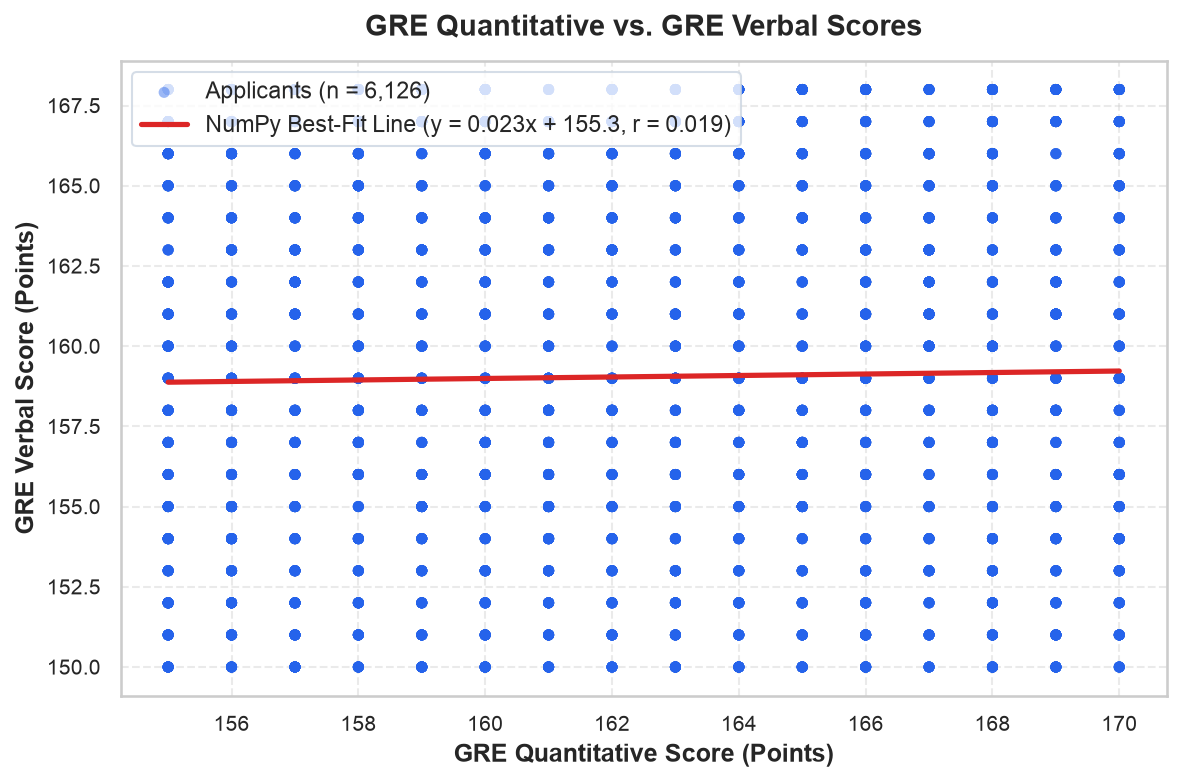

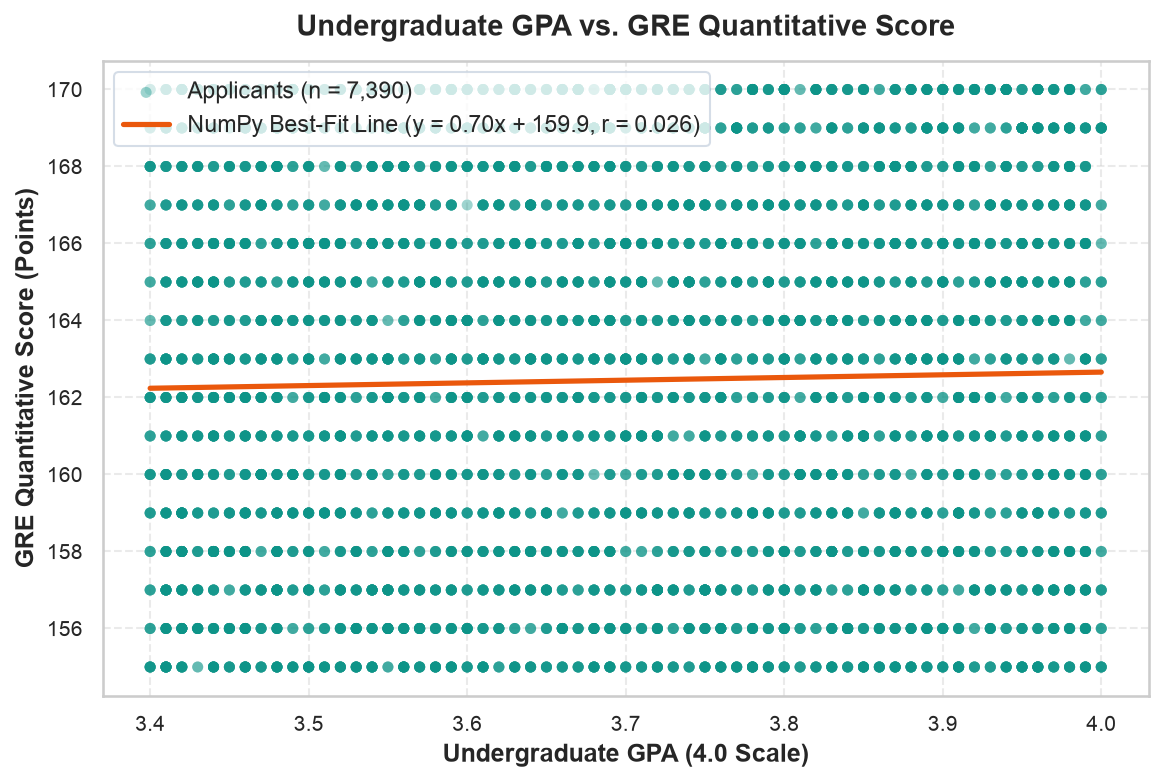

In [13]:
# Visualization 1: GRE Quantitative vs. GRE Verbal
fig, ax = plt.subplots(figsize=(9, 5.5))
x_vals1 = gre_verbal_paired["GRE"].values
y_vals1 = gre_verbal_paired["GRE V"].values
ax.scatter(x_vals1, y_vals1, color="#2563eb", alpha=0.45, edgecolors="none", s=28, label=f"Applicants (n = {len(gre_verbal_paired):,})")

# Best-fit line via NumPy
slope1, intercept1 = np.polyfit(x_vals1, y_vals1, 1)
x_line1 = np.linspace(x_vals1.min(), x_vals1.max(), 100)
y_line1 = slope1 * x_line1 + intercept1
ax.plot(x_line1, y_line1, color="#dc2626", linewidth=2.5, label=f"NumPy Best-Fit Line (y = {slope1:.3f}x + {intercept1:.1f}, r = {r_gre_verbal:.3f})")

ax.set_title("GRE Quantitative vs. GRE Verbal Scores", pad=12)
ax.set_xlabel("GRE Quantitative Score (Points)")
ax.set_ylabel("GRE Verbal Score (Points)")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(frameon=True, facecolor="white", edgecolor="#cbd5e1", loc="upper left")
plt.savefig("GRE-vs-GRE-V.png")
plt.show()

# Visualization 2: Undergraduate GPA vs. GRE Quantitative
fig, ax = plt.subplots(figsize=(9, 5.5))
x_vals2 = gpa_gre_paired["GPA"].values
y_vals2 = gpa_gre_paired["GRE"].values
ax.scatter(x_vals2, y_vals2, color="#0d9488", alpha=0.40, edgecolors="none", s=28, label=f"Applicants (n = {len(gpa_gre_paired):,})")

slope2, intercept2 = np.polyfit(x_vals2, y_vals2, 1)
x_line2 = np.linspace(x_vals2.min(), x_vals2.max(), 100)
y_line2 = slope2 * x_line2 + intercept2
ax.plot(x_line2, y_line2, color="#ea580c", linewidth=2.5, label=f"NumPy Best-Fit Line (y = {slope2:.2f}x + {intercept2:.1f}, r = {r_gpa_gre:.3f})")

ax.set_title("Undergraduate GPA vs. GRE Quantitative Score", pad=12)
ax.set_xlabel("Undergraduate GPA (4.0 Scale)")
ax.set_ylabel("GRE Quantitative Score (Points)")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(frameon=True, facecolor="white", edgecolor="#cbd5e1", loc="upper left")
plt.savefig("GPA-vs-GRE.png")
plt.show()

findfont: Failed to find font weight semibold for Arial, now using 700.


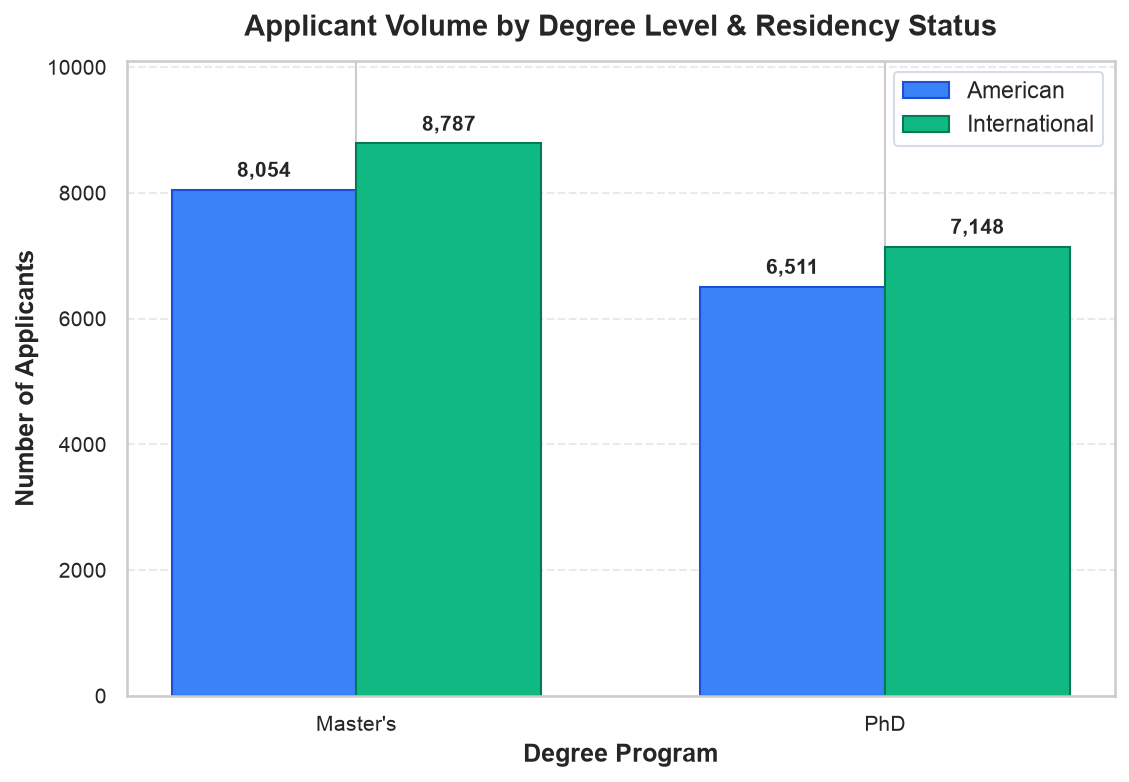

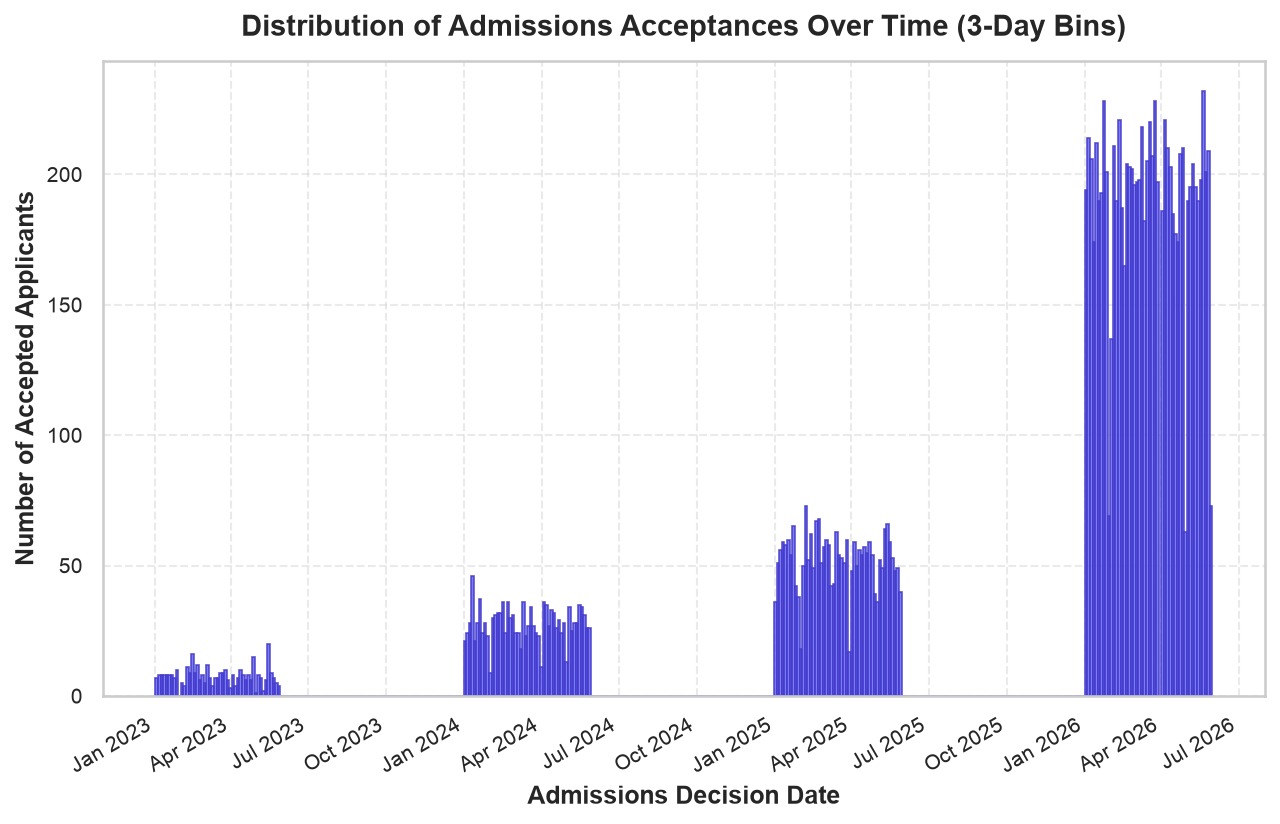

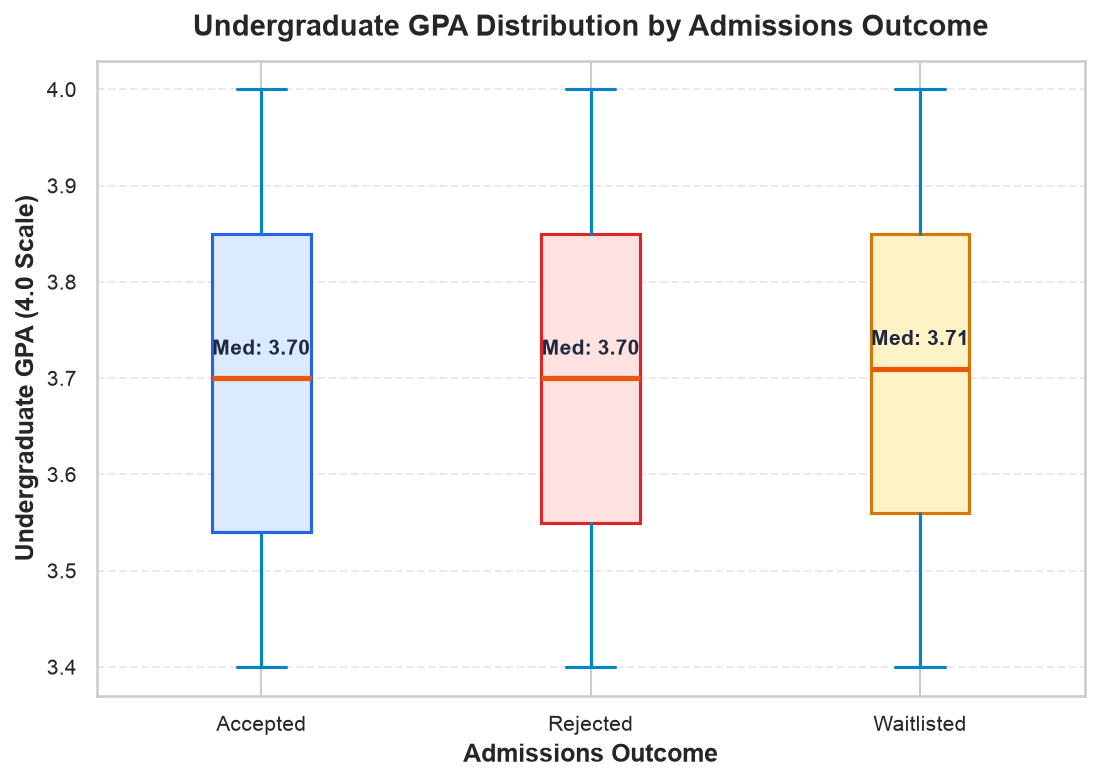

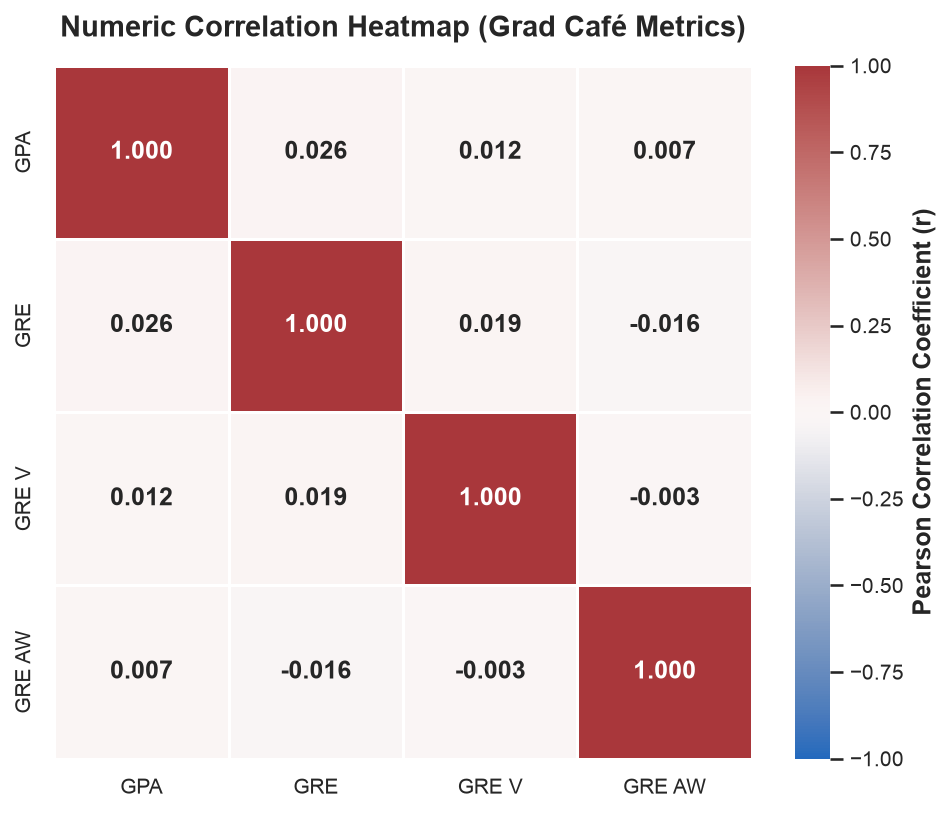

In [14]:
# Visualization 3: Degree vs. International Residency Bar Chart
fig, ax = plt.subplots(figsize=(8.5, 5.5))
degree_cats = ["Master's", "PhD"]
ct_subset = contingency_degree_intl.loc[degree_cats, ["American", "International"]]
indices = np.arange(len(degree_cats))
bar_width = 0.35

rects_us = ax.bar(indices - bar_width/2, ct_subset["American"], bar_width, label="American", color="#3b82f6", edgecolor="#1d4ed8", linewidth=1)
rects_intl = ax.bar(indices + bar_width/2, ct_subset["International"], bar_width, label="International", color="#10b981", edgecolor="#047857", linewidth=1)

ax.set_title("Applicant Volume by Degree Level & Residency Status", pad=12)
ax.set_xlabel("Degree Program")
ax.set_ylabel("Number of Applicants")
ax.set_xticks(indices)
ax.set_xticklabels(degree_cats)
ax.grid(True, axis="y", linestyle="--", alpha=0.4)
ax.legend(frameon=True, facecolor="white", edgecolor="#cbd5e1", loc="upper right")

for rect in rects_us + rects_intl:
    h = rect.get_height()
    ax.annotate(f"{h:,}", xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=10, weight="semibold")
ax.set_ylim(0, max(ct_subset.max()) * 1.15)
plt.savefig("Degree-vs-International.png")
plt.show()

# Visualization 4: Acceptances Over Time (3-Day Intervals)
fig, ax = plt.subplots(figsize=(10, 5.5))
accepted_dates = cleaned_df[cleaned_df["outcome"] == "Accepted"]["decision_date"].dropna()
start_date = accepted_dates.min().floor("D")
end_date = accepted_dates.max().ceil("D") + pd.Timedelta(days=3)
date_bins = pd.date_range(start=start_date, end=end_date, freq="3D")

ax.hist(accepted_dates, bins=date_bins, color="#6366f1", edgecolor="#4338ca", linewidth=0.8, alpha=0.85)
ax.set_title("Distribution of Admissions Acceptances Over Time (3-Day Bins)", pad=12)
ax.set_xlabel("Admissions Decision Date")
ax.set_ylabel("Number of Accepted Applicants")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax.grid(True, linestyle="--", alpha=0.4)
plt.savefig("Acceptances-over-Time.png")
plt.show()

# Visualization 5: GPA Distribution by Outcome Boxplot
fig, ax = plt.subplots(figsize=(8.5, 5.5))
outcomes = ["Accepted", "Rejected", "Waitlisted"]
box_arrays = [cleaned_df[(cleaned_df["outcome"] == out) & (cleaned_df["has_valid_gpa"] == 1)]["GPA"].values for out in outcomes]

bp = ax.boxplot(box_arrays, patch_artist=True, tick_labels=outcomes,
                boxprops=dict(facecolor="#e0f2fe", color="#0284c7", linewidth=1.5),
                whiskerprops=dict(color="#0284c7", linewidth=1.5),
                capprops=dict(color="#0284c7", linewidth=1.5),
                medianprops=dict(color="#ea580c", linewidth=2.5),
                flierprops=dict(marker="o", markerfacecolor="#94a3b8", markeredgecolor="none", markersize=3, alpha=0.5))

box_colors = ["#dbeafe", "#fee2e2", "#fef3c7"]
border_colors = ["#2563eb", "#dc2626", "#d97706"]
for patch, c, b in zip(bp["boxes"], box_colors, border_colors):
    patch.set_facecolor(c)
    patch.set_edgecolor(b)

ax.set_title("Undergraduate GPA Distribution by Admissions Outcome", pad=12)
ax.set_xlabel("Admissions Outcome")
ax.set_ylabel("Undergraduate GPA (4.0 Scale)")
ax.grid(True, axis="y", linestyle="--", alpha=0.4)
for i, out_name in enumerate(outcomes):
    med = np.median(box_arrays[i])
    ax.text(i + 1, med + 0.02, f"Med: {med:.2f}", ha="center", va="bottom", fontsize=10, weight="bold", color="#1e293b")
plt.savefig("GPA-by-Outcome.png")
plt.show()

# Visualization 6: Numeric Correlation Heatmap
fig, ax = plt.subplots(figsize=(7.5, 6))
corr_matrix = cleaned_df[target_numerics].corr(method="pearson")
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="vlag", vmin=-1.0, vmax=1.0,
            cbar_kws={"label": "Pearson Correlation Coefficient (r)"},
            linewidths=1.2, linecolor="white", ax=ax, annot_kws={"size": 12, "weight": "semibold"})
ax.set_title("Numeric Correlation Heatmap (Grad Café Metrics)", pad=14)
plt.savefig("Numeric-Correlation-Heatmap.png")
plt.show()

## 8. Cleaned Dataset Export, Amazon S3 Upload & Resource Shutdown
Export the final cleaned DataFrame to `cleaned_gradcafe.json`, persist it back into the designated S3 bucket via `boto3`, and issue a completion verification log.

> **Important Cloud Hygiene Reminder:** Stop your Amazon SageMaker notebook instance immediately after execution to prevent unnecessary cloud compute billing.

In [15]:
# Export final cleaned DataFrame to JSON format
cleaned_json_path = "cleaned_gradcafe.json"
export_dataframe = cleaned_df.copy()

# Format timestamps to ISO date strings for clean JSON serialization
export_dataframe["date_added"] = export_dataframe["date_added"].dt.strftime("%Y-%m-%d")
export_dataframe["decision_date"] = export_dataframe["decision_date"].dt.strftime("%Y-%m-%d")

export_dataframe.to_json(cleaned_json_path, orient="records", indent=2)
file_size_clean_mb = os.path.getsize(cleaned_json_path) / (1024 * 1024)
print(f"[✓] Successfully exported cleaned dataset: {cleaned_json_path} ({len(export_dataframe):,} records, {file_size_clean_mb:.2f} MB)")

# Upload cleaned_gradcafe.json back to Amazon S3
try:
    print(f"[*] Uploading {cleaned_json_path} to s3://{BUCKET_NAME}/{cleaned_json_path}...")
    s3_client.upload_file(cleaned_json_path, BUCKET_NAME, cleaned_json_path)
    print(f"[✓] S3 Upload Succeeded: s3://{BUCKET_NAME}/{cleaned_json_path}")
    print(f"[✓] All Module 8 pipeline operations completed successfully!")
except Exception as upload_err:
    print(f"[!] S3 upload notice: {upload_err}")

print("\n[!] NOTE: Please remember to STOP your Amazon SageMaker notebook instance in the AWS Console to terminate compute billing.")

[✓] Successfully exported cleaned dataset: cleaned_gradcafe.json (30,500 records, 23.57 MB)
[*] Uploading cleaned_gradcafe.json to s3://grad-cafe-nf-594366804861/cleaned_gradcafe.json...


[✓] S3 Upload Succeeded: s3://grad-cafe-nf-594366804861/cleaned_gradcafe.json
[✓] All Module 8 pipeline operations completed successfully!

[!] NOTE: Please remember to STOP your Amazon SageMaker notebook instance in the AWS Console to terminate compute billing.
